### Top Rows

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

file_path = "results-filtered.csv"
df = pd.read_csv(file_path)
for v in "v0 v1 v4".split(): 
    df[f"{v}-prep"] = df[f"{v}-S-bnb"]=="prep"
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)




=== A wins (speedup >= 2) ===
      v0-ctcp  v1-ctcp  speedup_a
144    0.3005   3.9984  13.305824
145    0.2713   4.4192  16.288979
146    0.2971   3.9314  13.232582
147    0.2674   4.2102  15.744951
148    0.2895   4.3954  15.182729
...       ...      ...        ...
4351   0.9654  35.5703  36.845142
4352   1.0000  32.3478  32.347800
4353   1.2062  31.1916  25.859393
4354   1.0365  29.3693  28.335070
4355   1.2162  24.5983  20.225539

[1154 rows x 3 columns]

=== B wins (speedup >= 2) ===
      v0-ctcp  v1-ctcp  speedup_b
1261   1.5141   0.7443   2.034260
1262   1.3896   0.5966   2.329199
1263   1.5221   0.5061   3.007508
3044   1.0316   0.4293   2.402982
3056   1.1564   0.5731   2.017798
3057   1.2339   0.5663   2.178880
3058   1.1499   0.5598   2.054126
3061   1.2378   0.5572   2.221464
3062   1.1749   0.5585   2.103671
3063   1.2397   0.5518   2.246647
3067   1.2699   0.6204   2.046905
3068   1.3039   0.6213   2.098664
3069   1.2404   0.6142   2.019538
3136   1.1836   0.2020   5.85

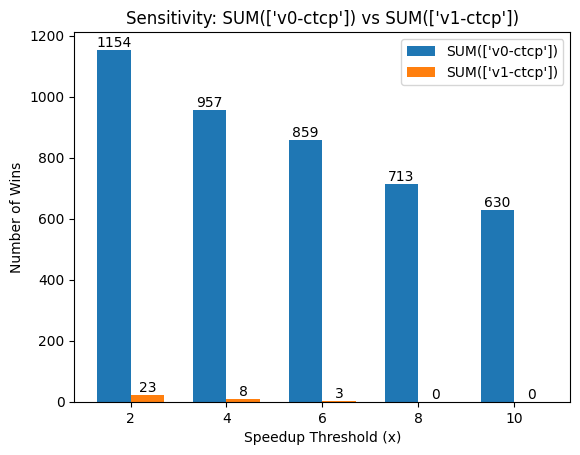

In [3]:
# =========================
# CONFIG
# =========================
cols_a = ["v0-ctcp"]
cols_b = ["v1-ctcp"]

thresholds = [2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.001)

# =========================
# Compute sums
# =========================
df["sum_a"] = df[cols_a].sum(axis=1)
df["sum_b"] = df[cols_b].sum(axis=1)

# =========================
# Filter small runtimes
# =========================
df_filtered = df[(df["sum_a"] >= min_time_threshold) | (df["sum_b"] >= min_time_threshold)].copy()

# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered["sum_b"] / df_filtered["sum_a"]
df_filtered["speedup_b"] = df_filtered["sum_a"] / df_filtered["sum_b"]

# =========================
# PRINT winning cases for threshold = 2
# =========================
threshold_check = 2

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check]
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check]

print(f"\n=== A wins (speedup >= {threshold_check}) ===")
print(a_wins[[*cols_a, *cols_b, "speedup_a"]])

print(f"\n=== B wins (speedup >= {threshold_check}) ===")
print(b_wins[[*cols_a, *cols_b, "speedup_b"]])

# =========================
# Evaluate across thresholds
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot (grouped bar chart)
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=f"SUM({cols_a})")
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=f"SUM({cols_b})")

# =========================
# Annotate bars
# =========================
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

# =========================
# Labels & title
# =========================
plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of Wins")
plt.title(f"Sensitivity: SUM({cols_a}) vs SUM({cols_b})")

plt.legend()

plt.show()

### Varying Ratio Threshold


=== Threshold 2 Analysis ===
v0-ctcp wins: 407
v4-ctcp wins: 116

Weaker side: col_b
Sorted in descending order of speedup:



,dataset,k,v0-ctcp,v4-ctcp,speedup_b,v0-heur,v4-heur,v0-prep,v4-prep,v0-S-total,v4-S-total,v0-R-total,v4-R-total,v0-P-total,v4-P-total
507,bibd_22_8,20,96.6,1.7,57.0,0.2,19.7,False,False,1800.0,1800.0,1800.0,650.4,1325.4,936.6
3457,soc-FourSqua...,10,5.7,0.3,18.0,0.4,0.0,False,False,7.9,0.3,8.4,0.3,7.8,0.3
491,bibd_19_9,20,7.1,0.6,12.6,0.1,1.8,False,False,1800.0,1800.0,1225.4,86.8,20.9,16.2
489,bibd_18_9,20,3.0,0.2,12.3,0.1,0.9,False,False,1800.0,1800.0,371.5,74.7,7.0,4.5
759,connectus,15,1.0,0.1,9.9,0.1,0.5,False,False,1800.0,1800.0,43.9,52.9,21.1,8.2
3456,soc-FourSqua...,9,2.6,0.3,9.6,0.4,0.0,False,False,3.9,0.3,3.8,0.3,3.9,0.3
2559,pics_ti,10,1.4,0.1,9.3,0.1,0.0,False,True,1.8,0.1,1.8,0.1,1.8,0.1
3487,soc-livejour...,10,1077.7,124.4,8.7,59.1,147.9,False,False,1800.0,312.9,1800.0,310.0,1800.0,318.4
1829,jester2,7,1.4,0.2,8.3,0.4,0.0,False,True,1.5,0.2,1.7,0.2,1.5,0.2
3458,soc-FourSqua...,15,2.7,0.3,8.2,0.4,0.2,False,False,6.0,0.5,1800.0,0.8,6.1,0.5


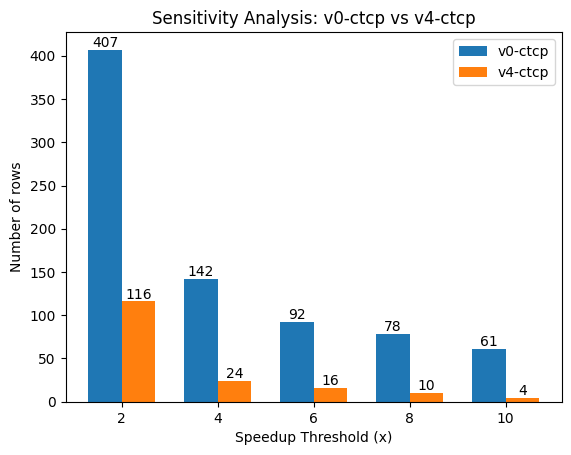

In [17]:
# =========================
# CONFIG
# =========================
col_a = "v0-ctcp"
col_b = "v4-ctcp"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================


df_filtered = df[(df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)].copy()
# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = 2

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# Determine weaker side
if len(a_wins) < len(b_wins):
    weaker = "A"
    weaker_df = a_wins.sort_values(by="v4-ctcp", ascending=False)
    speed_col = "speedup_a"
    wc=col_a.split("-")[0]
elif len(b_wins) < len(a_wins):
    weaker = "B"
    weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
    speed_col = "speedup_b"
    wc=col_b.split("-")[0]
else:
    weaker = "Tie"
    weaker_df = None
pd.set_option('display.float_format', '{:.1f}'.format)
# =========================
# Print weaker side
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)



if weaker == "Tie":
    print("Both sides have equal wins.")
else:
    print(f"\nWeaker side: {'col_a' if weaker == 'A' else 'col_b'}")
    print("Sorted in descending order of speedup:\n")
    max_len = 12  # choose what you like

    display(
        weaker_df.assign(
            dataset=weaker_df["dataset"].apply(
                lambda x: x[:max_len] + "..." if len(x) > max_len else x
            )
        )[["dataset", "k", col_a, col_b, speed_col, f"{va}-heur", f"{vb}-heur", f"{va}-prep", f"{vb}-prep", f"{va}-S-total", f"{vb}-S-total", f"{va}-R-total", f"{vb}-R-total",f"{va}-P-total",  f"{vb}-P-total"]]
    )

# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

# Annotate
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()